# 2026-06-25 OD600 — phage infection time-course (9-6-2 & 9-2-1 + p8)

Growth/lysis curves for **two host strains** (9-6-2, 9-2-1), each challenged with its phage
**p8**. This is the *redo* with a slightly different approach: instead of waiting for OD 0.4,
phage is added at a **fixed time**.

## Phage-addition event (the key change)
At **8:08 pm (20:08)** the non-control cultures were **transferred to a smaller tube and phage
was added**, diluting them to a theoretical **3/4** of their original concentration. This happens
**between the t=6 (7:37 pm) and t=7 (8:37 pm) readings**, so:
- `PHAGE_ADDED_AFTER_T = 6` — t ≤ 6 is **pre-phage**, t ≥ 7 is **post-phage**.
- At t=7 every tube's OD drops sharply. For the phage tubes this is the 3/4 dilution (plus any
  early lysis); the **controls also dip** (~0.56–0.60×) — treated here as a **transient artifact
  of the container change**, so per the bench note the controls are left **un-normalized**.

## Three views of the curves (§3)
Because the phage-addition step is a discontinuity, the timecourse is shown as three plots rather
than one continuous curve:
1. **Pre-phage** (t ≤ 6) — growth before anything was added.
2. **Post-phage** (t ≥ 7) — the infection window on its own axis.
3. **Normalized continuous** — pre-phage **non-control** values × 3/4 (controls unchanged) so the
   pre/post halves line up; lysis then shows as phage tubes falling below the control trajectory.

## Samples (6 total)
| column | strain | condition | phage |
|---|---|---|---|
| `9-6-2_control` | 9-6-2 | no-phage control | none |
| `9-6-2_1`, `9-6-2_2` | 9-6-2 | + phage | 9-6-2 p8 (2 replicates) |
| `9-2-1_control` | 9-2-1 | no-phage control | none |
| `9-2-1_1`, `9-2-1_2` | 9-2-1 | + phage | 9-2-1 p8 (2 replicates) |

## How to log data (at the bench)
Fill in [`../data/assays/0625_od600_phage(9-6-2_p8, 9-2-1_p8).csv`](../data/assays/0625_od600_phage%289-6-2_p8%2C%209-2-1_p8%29.csv)
— wide format, one row per hour: `date`, `time` (hh:mm), `t`, then one OD600 column per tube.
Leave a cell blank until that reading is taken. Re-run the notebook to refresh the plots.

In [77]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data/assays/0625_od600_phage(9-6-2_p8, 9-2-1_p8).csv")
OUT = Path("output/0625_od600_phage")
OUT.mkdir(parents=True, exist_ok=True)

PHAGE_ADDED_AFTER_T = 6      # phage added at 8:08 pm, AFTER the t=6 (7:37 pm) reading
PHAGE_ADDED_CLOCK   = "20:08"
POST_DILUTION       = 3/4    # non-control tubes diluted to 3/4 of original conc. at phage addition

STRAINS = ["9-6-2", "9-2-1"]

# Fixed experiment design — column -> metadata.
SAMPLES = pd.DataFrame([
    ("9-6-2_control", "9-6-2", "control", "9-6-2 control", "none",     0),
    ("9-6-2_1",       "9-6-2", "phage",   "9-6-2 +p8",     "9-6-2 p8", 1),
    ("9-6-2_2",       "9-6-2", "phage",   "9-6-2 +p8",     "9-6-2 p8", 2),
    ("9-2-1_control", "9-2-1", "control", "9-2-1 control", "none",     0),
    ("9-2-1_1",       "9-2-1", "phage",   "9-2-1 +p8",     "9-2-1 p8", 1),
    ("9-2-1_2",       "9-2-1", "phage",   "9-2-1 +p8",     "9-2-1 p8", 2),
], columns=["sample", "strain", "condition", "group", "phage", "replicate"])
SAMPLE_COLS = SAMPLES["sample"].tolist()
CTRL_OF = {st: f"{st}_control" for st in STRAINS}   # each strain's own control column

STRAIN_CMAP = {"9-6-2": plt.cm.Blues, "9-2-1": plt.cm.Oranges}
def strain_color(meta):
    cmap = STRAIN_CMAP[meta["strain"]]
    return cmap(0.92) if meta["condition"] == "control" else cmap(0.45 + 0.18 * meta["replicate"])
SAMPLES

,sample,strain,condition,group,phage,replicate
0,9-6-2_control,9-6-2,control,9-6-2 control,none,0
1,9-6-2_1,9-6-2,phage,9-6-2 +p8,9-6-2 p8,1
2,9-6-2_2,9-6-2,phage,9-6-2 +p8,9-6-2 p8,2
3,9-2-1_control,9-2-1,control,9-2-1 control,none,0
4,9-2-1_1,9-2-1,phage,9-2-1 +p8,9-2-1 p8,1
5,9-2-1_2,9-2-1,phage,9-2-1 +p8,9-2-1 p8,2


## 1 · Load readings

Reads the wide CSV and melts it to tidy long form (`t, sample, od600`) joined to the sample
metadata. A `phase` column tags each reading pre- vs post-phage, and `od_norm` holds the
normalized OD (pre-phage **non-control** × 3/4; everything else unchanged) used for the
continuous view in §3.3. Blank cells are unrecorded readings and are dropped.

In [78]:
wide = pd.read_csv(DATA)
for c in SAMPLE_COLS:
    wide[c] = pd.to_numeric(wide[c], errors="coerce")

data = (wide.melt(id_vars=["date", "time", "t"], value_vars=SAMPLE_COLS,
                  var_name="sample", value_name="od600")
            .dropna(subset=["od600"])
            .merge(SAMPLES, on="sample", how="left")
            .sort_values(["sample", "t"]))

data["phase"] = np.where(data["t"] <= PHAGE_ADDED_AFTER_T, "pre", "post")
# normalized OD: scale pre-phage NON-control readings by 3/4 so they sit on the post-phage
# (diluted) scale; controls and all post-phage readings are left as measured.
norm_mask = (data["condition"] != "control") & (data["t"] <= PHAGE_ADDED_AFTER_T)
data["od_norm"] = data["od600"].where(~norm_mask, data["od600"] * POST_DILUTION)

n_read = len(data)
print(f"{n_read} OD readings across {data['sample'].nunique()}/6 tubes — "
      f"{(data['phase']=='pre').sum()} pre-phage, {(data['phase']=='post').sum()} post-phage")
print(f"Phage added at {PHAGE_ADDED_CLOCK} (after t={PHAGE_ADDED_AFTER_T}); "
      f"non-control pre-phage OD scaled by {POST_DILUTION:.2f} for the normalized view.")
wide

102 OD readings across 6/6 tubes — 42 pre-phage, 60 post-phage
Phage added at 20:08 (after t=6); non-control pre-phage OD scaled by 0.75 for the normalized view.


,date,time,t,9-6-2_control,9-6-2_1,9-6-2_2,9-2-1_control,9-2-1_1,9-2-1_2
0,2026-06-25,13:37,0,0.105,0.018,0.015,0.108,0.011,0.013
1,2026-06-25,14:37,1,0.075,0.024,0.020,0.071,0.015,0.019
2,2026-06-25,15:37,2,0.110,0.049,0.042,0.115,0.046,0.047
3,2026-06-25,16:37,3,0.152,0.066,0.065,0.146,0.060,0.061
4,2026-06-25,17:37,4,0.157,0.077,0.066,0.146,0.079,0.068
...,...,...,...,...,...,...,...,...,...
69,2026-06-28,10:37,69,NaN,NaN,NaN,NaN,NaN,NaN
70,2026-06-28,11:37,70,NaN,NaN,NaN,NaN,NaN,NaN
71,2026-06-28,12:37,71,NaN,NaN,NaN,NaN,NaN,NaN
72,2026-06-28,13:37,72,NaN,NaN,NaN,NaN,NaN,NaN


## 2 · The phage-addition step

A look at the readings straddling the 8:08 pm addition (t=6 → t=7): every tube drops. For the
phage tubes the expected drop is the 3/4 dilution; anything **below** 3/4 is extra loss (early
lysis). The controls also dip — taken as a transient container-change artifact.

In [79]:
b = (wide[wide["t"].isin([PHAGE_ADDED_AFTER_T, PHAGE_ADDED_AFTER_T + 1])]
        .set_index("t")[SAMPLE_COLS])
if len(b) == 2:
    t6, t7 = PHAGE_ADDED_AFTER_T, PHAGE_ADDED_AFTER_T + 1
    ratio = (b.loc[t7] / b.loc[t6]).rename("t7/t6 ratio")
    tbl = pd.DataFrame({f"t{t6} (pre)": b.loc[t6], f"t{t7} (post)": b.loc[t7],
                        "observed ratio": ratio.round(3),
                        "expected (dilution)": [1.0 if c.endswith("_control") else POST_DILUTION
                                                for c in SAMPLE_COLS]})
    print(f"Dilution check across the {PHAGE_ADDED_CLOCK} addition "
          f"(phage tubes expected ~{POST_DILUTION:.2f}, controls ~1.0):")
    display(tbl)
else:
    print("Need both the t=6 and t=7 readings to show the addition step.")

Dilution check across the 20:08 addition (phage tubes expected ~0.75, controls ~1.0):


,t6 (pre),t7 (post),observed ratio,expected (dilution)
9-6-2_control,0.260,0.146,0.562,1.00
9-6-2_1,0.185,0.123,0.665,0.75
9-6-2_2,0.167,0.089,0.533,0.75
9-2-1_control,0.276,0.167,0.605,1.00
9-2-1_1,0.182,0.090,0.495,0.75
9-2-1_2,0.180,0.065,0.361,0.75


## 3 · Curves

One line per tube — each strain in its own colour family (9-6-2 blues, 9-2-1 oranges); controls
are dashed squares, phage replicates solid circles. The grey dashed line marks the 8:08 pm phage
addition. Infection is read **visually**: after addition, phage tubes that fall away from their
strain's control (clearest on the normalized plot §3.3) are lysing.

In [80]:
def plot_curves(df, ycol, title, fname, xwindow=None, ylabel=None):
    """One line per tube over the given dataframe / y-column."""
    fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)
    drawn = False
    for _, meta in SAMPLES.iterrows():
        sub = df[df["sample"] == meta["sample"]].sort_values("t")
        if sub.empty:
            continue
        is_ctrl = meta["condition"] == "control"
        ax.plot(sub["t"], sub[ycol], ls="--" if is_ctrl else "-",
                marker="s" if is_ctrl else "o", ms=5 if is_ctrl else 4,
                color=strain_color(meta), label=meta["sample"])
        drawn = True
    if not drawn:
        ax.text(0.5, 0.5, "no readings in this window yet", ha="center", va="center",
                transform=ax.transAxes, color="grey")
    ax.set_xlabel("t (h)")
    ax.set_ylabel(ylabel or ("OD600 (normalized)" if ycol == "od_norm" else "OD600"))
    ax.set_title(title)
    if xwindow:
        ax.set_xlim(*xwindow)
    top = max((df[ycol].max() * 1.2) if not df.empty else 0.3, 0.05)
    ax.set_ylim(0, top)
    # 8:08 pm phage-addition marker (drawn if inside the x-window)
    xlo, xhi = ax.get_xlim()
    xadd = PHAGE_ADDED_AFTER_T + 0.5
    if xlo <= xadd <= xhi:
        ax.axvline(xadd, ls=(0, (6, 4)), lw=1.4, color="purple", alpha=.8)
        ax.text(xadd, top * 0.98, f"phage added {PHAGE_ADDED_CLOCK}", rotation=90,
                va="top", ha="right", fontsize=8, color="purple")
    ax.legend(ncol=1, fontsize=8, title="dashed = control",
              loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.savefig(OUT / fname, dpi=150, bbox_inches="tight")
    plt.show()
    return ax

### 3.1 · Pre-phage (t ≤ 6, up to the 7:37 pm reading)

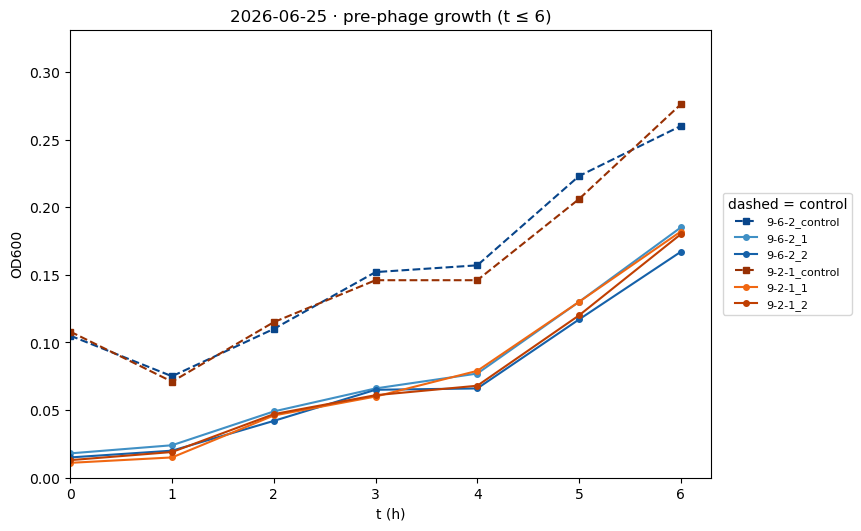

<Axes: title={'center': '2026-06-25 · pre-phage growth (t ≤ 6)'}, xlabel='t (h)', ylabel='OD600'>

In [81]:
pre = data[data["phase"] == "pre"]
plot_curves(pre, "od600",
            "2026-06-25 · pre-phage growth (t ≤ 6)",
            "2026-06-25_curves_pre-phage.png",
            xwindow=(0, PHAGE_ADDED_AFTER_T + 0.3))

### 3.2 · Post-phage (t ≥ 7, from the 8:37 pm reading)

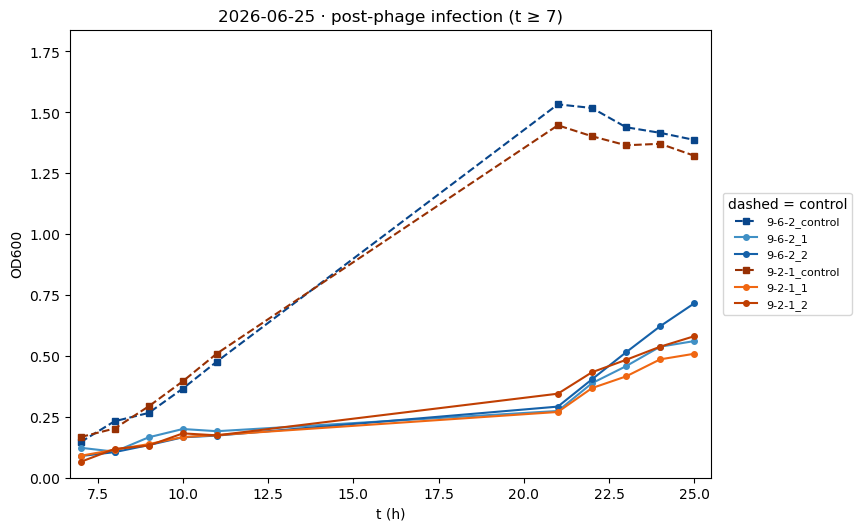

In [82]:
post = data[data["phase"] == "post"]
if post.empty:
    print("No post-phage readings yet (t >= 7) — fill the CSV and re-run.")
else:
    xhi = post["t"].max() + 0.5
    plot_curves(post, "od600",
                f"2026-06-25 · post-phage infection (t ≥ {PHAGE_ADDED_AFTER_T + 1})",
                "2026-06-25_curves_post-phage.png",
                xwindow=(PHAGE_ADDED_AFTER_T + 0.7, xhi))

### 3.3 · Normalized continuous (pre-phage non-control × 3/4)

Pre-phage **non-control** readings are scaled by 3/4 so they sit on the post-phage (diluted)
scale, giving one continuous trajectory across the addition. Controls are unchanged (so their
t=7 dip — the container artifact — is still visible). A phage tube dropping **below** its
strain's control after the line is the lysis signal.

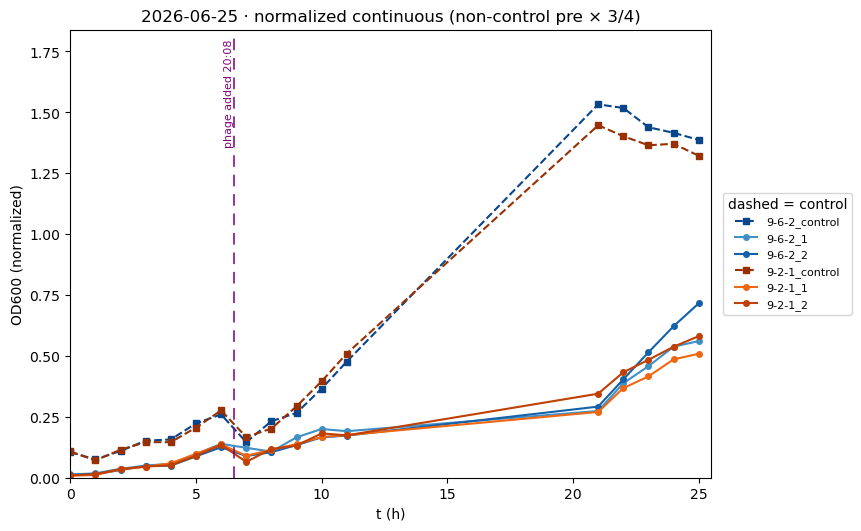

<Axes: title={'center': '2026-06-25 · normalized continuous (non-control pre × 3/4)'}, xlabel='t (h)', ylabel='OD600 (normalized)'>

In [83]:
plot_curves(data, "od_norm",
            "2026-06-25 · normalized continuous (non-control pre × 3/4)",
            "2026-06-25_curves_normalized.png",
            xwindow=(0, max(data["t"].max() + 0.5, PHAGE_ADDED_AFTER_T + 1)))

### 3.4 · Normalized continuous (control as the normalizer)

Same continuous view as §3.3, but instead of the theoretical 3/4 dilution factor, each strain's
pre-phage **non-control** readings are scaled by that strain's **measured control drop** across the
addition (control t7 / t6). The control underwent the same dilution + container artifact but no
lysis, so it is an empirical, per-strain estimate of the pure physical drop — bridging the boundary
without assuming the dilution was exactly 3/4. A phage tube falling below its control afterward is
the lysis signal. *(Falls back to 3/4 for a strain whose t6/t7 control reading is missing.)*

Per-strain control drop ratio (t7/t6) used as normalizer: 9-6-2=0.562, 9-2-1=0.605


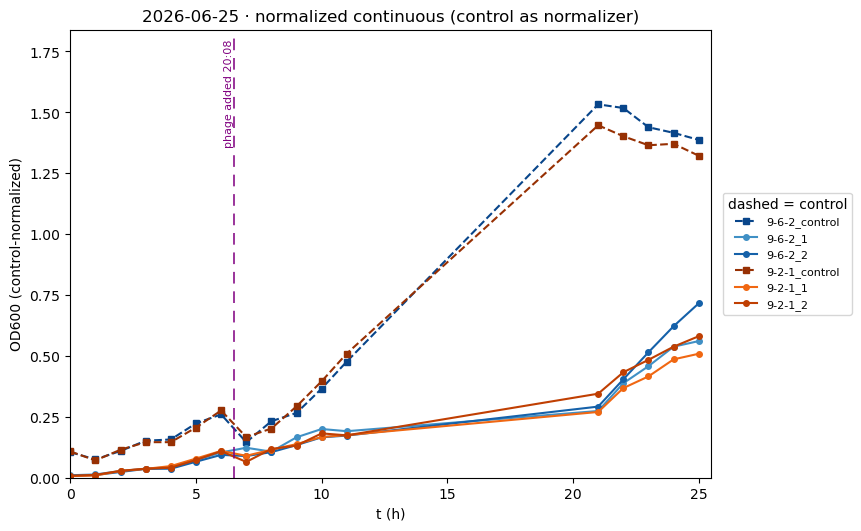

<Axes: title={'center': '2026-06-25 · normalized continuous (control as normalizer)'}, xlabel='t (h)', ylabel='OD600 (control-normalized)'>

In [84]:
t6, t7 = PHAGE_ADDED_AFTER_T, PHAGE_ADDED_AFTER_T + 1
r_ctrl = {}
for st in STRAINS:
    c = CTRL_OF[st]
    v6 = wide.loc[wide["t"] == t6, c]
    v7 = wide.loc[wide["t"] == t7, c]
    ok = (not v6.empty and not v7.empty and pd.notna(v6.iloc[0])
          and pd.notna(v7.iloc[0]) and v6.iloc[0] != 0)
    r_ctrl[st] = (v7.iloc[0] / v6.iloc[0]) if ok else POST_DILUTION
print("Per-strain control drop ratio (t7/t6) used as normalizer: "
      + ", ".join(f"{st}={r_ctrl[st]:.3f}" + ("" if (
          not wide.loc[wide['t']==t7, CTRL_OF[st]].empty
          and pd.notna(wide.loc[wide['t']==t7, CTRL_OF[st]].iloc[0])) else " [fallback 3/4]")
          for st in STRAINS))

data["od_ctrlnorm"] = data["od600"]
m = (data["condition"] != "control") & (data["t"] <= PHAGE_ADDED_AFTER_T)
data.loc[m, "od_ctrlnorm"] = data.loc[m, ["od600", "strain"]].apply(
    lambda r: r["od600"] * r_ctrl[r["strain"]], axis=1)

plot_curves(data, "od_ctrlnorm",
            "2026-06-25 · normalized continuous (control as normalizer)",
            "2026-06-25_curves_control-normalized.png",
            xwindow=(0, max(data["t"].max() + 0.5, PHAGE_ADDED_AFTER_T + 1)),
            ylabel="OD600 (control-normalized)")

## 4 · Post-phage growth fits (logistic)

A straight line is the wrong model here: over the post-phage window the **controls are sigmoidal**
(exponential growth levelling off toward a carrying capacity) and the phage tubes climb slowly
toward a much lower ceiling. So each tube is fit with a **logistic** curve

$$OD(t) = \dfrac{K}{1 + e^{-r\,(t - t_0)}}$$

which beat the alternatives on every tube (logistic R² 0.92–1.00 vs linear 0.83–0.998 vs
exponential 0.76–0.96). The two informative parameters are **K** — the carrying capacity (the
plateau OD the culture is heading to) — and **r** — the intrinsic growth rate (per h). The
headline: control and phage tubes grow at **similar rates r**, but phage caps the culture at a
**~5× lower density K**. *Caveat:* only ~6 post-phage points with a t=11→21 gap, so K (especially
for the still-rising phage tubes) is loosely constrained — provisional until the gap fills in.

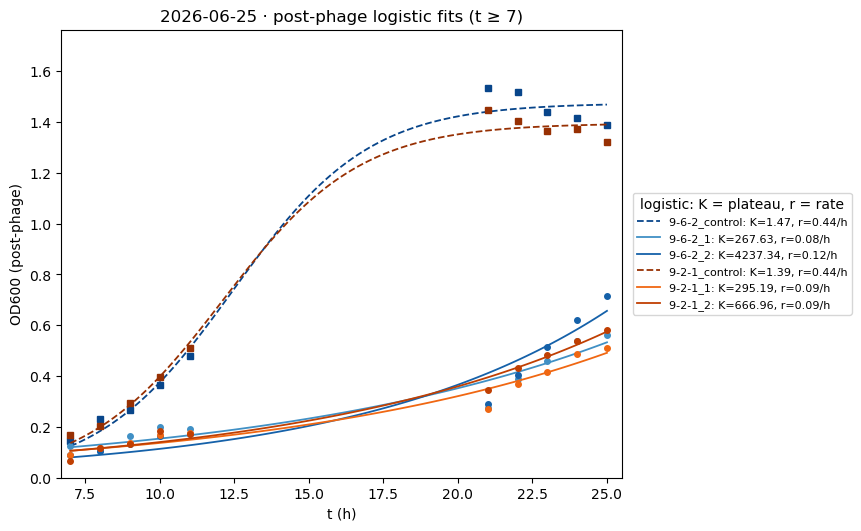

Post-phage logistic fits (K = carrying capacity, r = growth rate):


,tube,K (plateau OD),r (/h),t0 (h),R2,n
0,9-6-2_control,1.474,0.438,12.5,0.992,10
1,9-6-2_1,267.627,0.083,100.0,0.927,10
2,9-6-2_2,4237.337,0.117,100.0,0.939,10
3,9-2-1_control,1.395,0.435,12.1,0.995,10
4,9-2-1_1,295.187,0.085,100.0,0.956,10
5,9-2-1_2,666.964,0.094,100.0,0.980,10


  mean carrying capacity K — control: 1.43  (n=2)
  mean carrying capacity K — phage: 1366.78  (n=4)


In [85]:
from scipy.optimize import curve_fit

def logistic(t, K, r, t0):
    return K / (1 + np.exp(-r * (t - t0)))

post = data[data["phase"] == "post"]
fig, ax = plt.subplots(figsize=(8.5, 5.2), constrained_layout=True)
rows = []
if post.empty:
    print("No post-phage readings yet (t >= 7) — fill the CSV and re-run.")
else:
    for _, meta in SAMPLES.iterrows():
        s = meta["sample"]
        sub = post[post["sample"] == s].sort_values("t")
        if sub.empty:
            continue
        is_ctrl = meta["condition"] == "control"
        color = strain_color(meta)
        t = sub["t"].to_numpy(float); y = sub["od600"].to_numpy(float)
        ax.plot(t, y, ls="none", marker="s" if is_ctrl else "o",
                ms=5 if is_ctrl else 4, color=color)
        if len(sub) >= 4:   # logistic has 3 params; need a few points to fit
            try:
                popt, _ = curve_fit(logistic, t, y, p0=[max(y) * 1.2, 0.3, t.mean()],
                                    bounds=([0, 0, -50], [np.inf, 5, 100]), maxfev=20000)
                K, r, t0 = popt
                yh = logistic(t, *popt)
                ss = ((y - y.mean()) ** 2).sum()
                r2 = 1 - ((y - yh) ** 2).sum() / ss if ss > 0 else float("nan")
                tt = np.linspace(t.min(), t.max(), 100)
                ax.plot(tt, logistic(tt, *popt), ls="--" if is_ctrl else "-", lw=1.3,
                        color=color, label=f"{s}: K={K:.2f}, r={r:.2f}/h")
                rows.append((s, round(K, 3), round(r, 3), round(float(t0), 1), round(r2, 3), len(sub)))
            except Exception:
                rows.append((s, np.nan, np.nan, np.nan, np.nan, len(sub)))
        else:
            rows.append((s, np.nan, np.nan, np.nan, np.nan, len(sub)))

    ax.set_xlabel("t (h)"); ax.set_ylabel("OD600 (post-phage)")
    ax.set_title(f"2026-06-25 · post-phage logistic fits (t ≥ {PHAGE_ADDED_AFTER_T + 1})")
    ax.set_xlim(PHAGE_ADDED_AFTER_T + 0.7, post["t"].max() + 0.5)
    ax.set_ylim(0, max(post["od600"].max() * 1.15, 0.05))
    ax.legend(ncol=1, fontsize=8, title="logistic: K = plateau, r = rate",
              loc="center left", bbox_to_anchor=(1.01, 0.5))
    fig.savefig(OUT / "2026-06-25_post-phage_fits.png", dpi=150, bbox_inches="tight")
    plt.show()
    fits = pd.DataFrame(rows, columns=["tube", "K (plateau OD)", "r (/h)", "t0 (h)", "R2", "n"])
    print("Post-phage logistic fits (K = carrying capacity, r = growth rate):")
    display(fits)
    ok = fits.dropna(subset=["K (plateau OD)"]).merge(
        SAMPLES[["sample", "condition"]], left_on="tube", right_on="sample")
    for cond in ["control", "phage"]:
        sel = ok[ok["condition"] == cond]["K (plateau OD)"]
        if len(sel):
            print(f"  mean carrying capacity K — {cond}: {sel.mean():.2f}  (n={len(sel)})")

## 5 · Group means (per strain: control vs phage)

Phage replicates averaged per strain at each hour, on the **normalized** scale (so the curve is
continuous across the addition). The clean view of whether p8 collapses each strain relative to
its no-phage control.

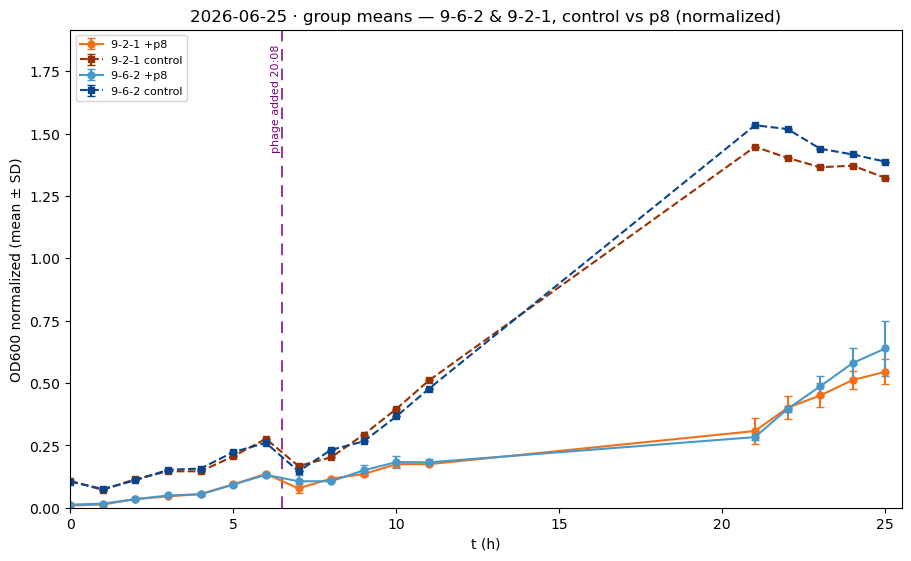

,group,strain,condition,t,mean,std,count
0,9-2-1 +p8,9-2-1,phage,0,0.009000,0.001061,2
1,9-2-1 +p8,9-2-1,phage,1,0.012750,0.002121,2
2,9-2-1 +p8,9-2-1,phage,2,0.034875,0.000530,2
3,9-2-1 +p8,9-2-1,phage,3,0.045375,0.000530,2
4,9-2-1 +p8,9-2-1,phage,4,0.055125,0.005834,2
...,...,...,...,...,...,...,...
63,9-6-2 control,9-6-2,control,21,1.533000,NaN,1
64,9-6-2 control,9-6-2,control,22,1.518000,NaN,1
65,9-6-2 control,9-6-2,control,23,1.439000,NaN,1
66,9-6-2 control,9-6-2,control,24,1.416000,NaN,1


In [86]:
if not data.empty:
    grp = (data.groupby(["group", "strain", "condition", "t"])["od_norm"]
               .agg(["mean", "std", "count"]).reset_index())
    fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)
    for (g, strain, cond), sub in grp.groupby(["group", "strain", "condition"]):
        cmap = STRAIN_CMAP[strain]
        ax.errorbar(sub["t"], sub["mean"], yerr=sub["std"].fillna(0),
                    marker="s" if cond == "control" else "o", ms=5, capsize=3,
                    ls="--" if cond == "control" else "-",
                    color=cmap(0.92) if cond == "control" else cmap(0.6), label=g)
    ax.set_xlabel("t (h)"); ax.set_ylabel("OD600 normalized (mean ± SD)")
    ax.set_title("2026-06-25 · group means — 9-6-2 & 9-2-1, control vs p8 (normalized)")
    ax.set_xlim(0, max(grp["t"].max() + 0.5, PHAGE_ADDED_AFTER_T + 1))
    gtop = max(grp["mean"].max() * 1.25, 0.05)
    ax.set_ylim(0, gtop)
    ax.axvline(PHAGE_ADDED_AFTER_T + 0.5, ls=(0, (6, 4)), lw=1.4, color="purple", alpha=.8)
    ax.text(PHAGE_ADDED_AFTER_T + 0.45, gtop * 0.97, f"phage added {PHAGE_ADDED_CLOCK}",
            rotation=90, va="top", ha="right", fontsize=8, color="purple")
    ax.legend(loc="upper left", fontsize=8)
    fig.savefig(OUT / "2026-06-25_group-means.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(grp)
else:
    print("No readings yet — fill the CSV and re-run.")